# YZM 411 - Bilgisayarlı Görü
## Ödev #1: Renk, Aydınlatma ve Örnekleme  
**Tarih:** 2026-2027 Güz Dönemi  

---
### Ödevin Amacı ve Kapsamı
Bu çalışmada, bir sahnenin üç farklı aydınlatma koşulunda (normal ışık, gölge ve farklı bir lamba) çekilmiş fotoğrafları üzerinden:
1. Görüntünün sayısal yapısı (H × W × C, veri türü, [y, x, c] erişimi, BGR/RGB dönüşümü),
2. Sabitlenmiş RGB ve HSV renk eşiklerinin aydınlatma değişimine duyarlılığı,
3. Parlaklık kaydırması ($b=+40$) ve gama dönüşümleri ($\gamma=0.5, \gamma=2.0$),
4. Örnekleme/küçültme yöntemlerinin (En Yakın Komşu ve Alan Ortalaması) bilgi kaybı ve örtüşme (aliasing) etkileri deneysel olarak incelenmektedir.


### 0. Ortam Kurulumu ve Görüntü Yolları
Google Drive'ı bağlayarak fotoğrafların bulunduğu klasör yolunu belirleyin.


In [ ]:
# @title 0. Google Drive Bağlantısı ve Dosya Yolları
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Google Drive'ı bağlama (Colab ortamında çalıştırıyorsanız)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive başarıyla bağlandı.")
except Exception as e:
    print("Colab Drive mount atlandı veya yerel ortamdasınız:", e)

# Paket sürümlerini doğrulama (Ödev teslim gereksinimi)
print("\n--- Paket Sürümleri ---")
print(f"OpenCV Sürümü     : {cv2.__version__}")
print(f"NumPy Sürümü      : {np.__version__}")
print(f"Pandas Sürümü     : {pd.__version__}")

# ==========================================
# FOTOĞRAF YOLLARINI BURADAN DÜZENLEYİN
# ==========================================
# Drive'a yüklediğiniz fotoğrafların tam yolunu girin:
IMAGE_LIGHT_PATH = "/content/drive/MyDrive/Computer Vision/image_light.jpg"  # Normal Işık
IMAGE_DARK_PATH  = "/content/drive/MyDrive/Computer Vision/image_dark.jpg"   # Gölge
IMAGE_LAMP_PATH  = "/content/drive/MyDrive/Computer Vision/image_lamp.jpg"   # Farklı bir lamba/sıcak ışık

# Test amaçlı: Dosyalar henüz Drive'da yoksa sentetik sahne oluşturan yedek kontrol
def load_or_create_dummy(path, mode="light"):
    if os.path.exists(path):
        bgr = cv2.imread(path)
        if bgr is not None:
            return bgr
    print(f"UYARI: '{path}' bulunamadı! Test amaçlı sentetik görüntü oluşturuluyor.")
    # Sentetik sahne: Sarı nesne, beyaz zemin/kağıt, gazete/yazı dokusu
    h, w = 600, 800
    img = np.zeros((h, w, 3), dtype=np.uint8)
    if mode == "light":
        bg_val, obj_bgr = 220, (30, 180, 230)      # Açık zemin, parlak sarı
    elif mode == "dark":
        bg_val, obj_bgr = 80, (12, 85, 110)        # Gölge, kararmış sarı
    else: # lamp (sıcak ışık / sarımsı kayma)
        bg_val, obj_bgr = 180, (20, 160, 245)
        img[:, :] = (120, 170, 220) # sarımsı arka plan
    if mode != "lamp":
        img[:, :] = (bg_val, bg_val, bg_val)

    # Renkli nesne (sarı dikdörtgen kutu)
    cv2.rectangle(img, (150, 150), (450, 450), obj_bgr, -1)
    # Beyaz kağıt
    cv2.rectangle(img, (500, 150), (750, 450), (245, 245, 245) if mode!="dark" else (100, 100, 100), -1)
    # Küçük puntolu yazı / çizgili doku (Örnekleme testi için)
    for y_line in range(200, 420, 14):
        cv2.putText(img, "YZM411 Bilgisayarli Goru 2026 Aliasing Test Text",
                    (510, y_line), cv2.FONT_HERSHEY_SIMPLEX, 0.32, (20, 20, 20), 1, cv2.LINE_AA)
    return img

bgr_light = load_or_create_dummy(IMAGE_LIGHT_PATH, "light")
bgr_dark  = load_or_create_dummy(IMAGE_DARK_PATH, "dark")
bgr_lamp  = load_or_create_dummy(IMAGE_LAMP_PATH, "lamp")

# BGR -> RGB Dönüşümü (OpenCV varsayılanı BGR'dir, Matplotlib ve sayısal analiz için RGB gerekir)
rgb_light = cv2.cvtColor(bgr_light, cv2.COLOR_BGR2RGB)
rgb_dark  = cv2.cvtColor(bgr_dark, cv2.COLOR_BGR2RGB)
rgb_lamp  = cv2.cvtColor(bgr_lamp, cv2.COLOR_BGR2RGB)

print("Tüm görüntüler başarıyla yüklendi ve RGB formatına dönüştürüldü.")


Mounted at /content/drive
Google Drive başarıyla bağlandı.

--- Paket Sürümleri ---
OpenCV Sürümü     : 5.0.0
NumPy Sürümü      : 2.4.6
Pandas Sürümü     : 2.2.3
Tüm görüntüler başarıyla yüklendi ve RGB formatına dönüştürüldü.


---
### 1. Görüntünün Sayısal Yapısını İnceleme (Hedef 1)
**Amaç:** Görüntünün matris/tensör yapısını, boyutunu ($H 	imes W 	imes C$), veri türünü, değer aralığını ve $[y, x, c]$ indis erişimini doğrulamak. Aynı fiziksel konumdaki 3 pikselin aydınlatma altında nasıl değiştiğini kaydetmek.


=== Görüntü Boyutları ve Veri Tipleri ===
Normal Işık  : Boyut=(4032, 3024, 3) (Yükseklik x Genişlik x Kanal), Tür=uint8, Aralık=[9, 255]
Gölge        : Boyut=(4032, 3024, 3), Tür=uint8, Aralık=[0, 118]
Farklı Lamba : Boyut=(4032, 3024, 3), Tür=uint8, Aralık=[0, 227]

=== Seçilen 3 Noktanın Üç Fotoğraftaki RGB Değerleri ===


,Nokta,"(x, y)",Normal Işık RGB,Gölge RGB,Lamba RGB
0,Nokta 1 (Renkli Nesne),"(1058, 1814)","(52, 49, 58)","(17, 15, 16)","(69, 59, 50)"
1,Nokta 2 (Beyaz Kağıt),"(2268, 1411)","(181, 184, 191)","(85, 86, 90)","(187, 177, 168)"
2,Nokta 3 (Doku/Zemin),"(2116, 2217)","(165, 163, 166)","(78, 78, 80)","(45, 45, 53)"


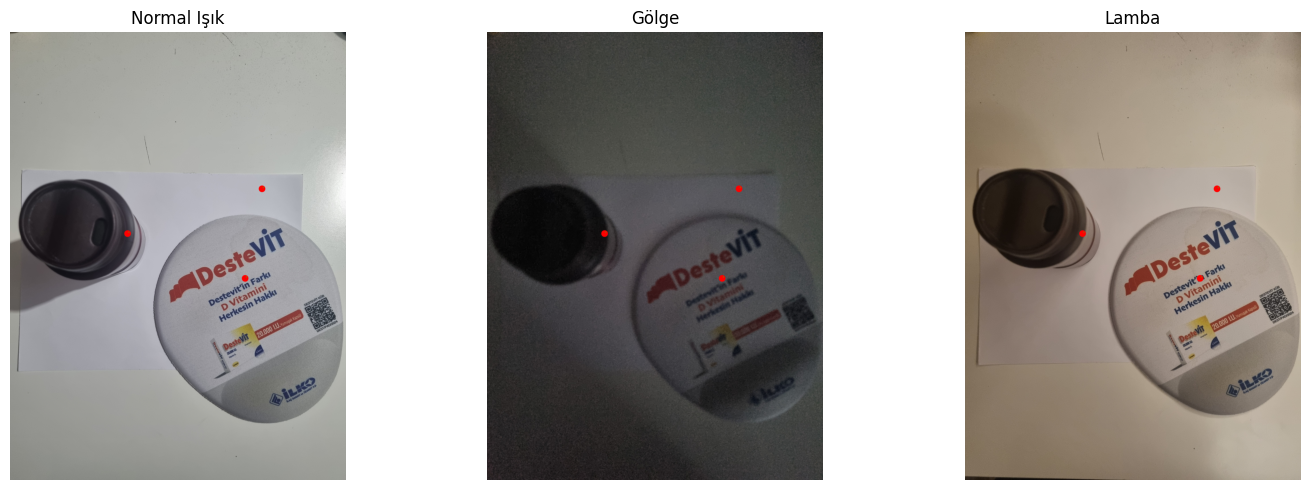

In [ ]:
# @title 1. Sayısal Yapı ve Seçilen 3 Pikselin İncelenmesi
print("=== Görüntü Boyutları ve Veri Tipleri ===")
print(f"Normal Işık  : Boyut={rgb_light.shape} (Yükseklik x Genişlik x Kanal), Tür={rgb_light.dtype}, Aralık=[{rgb_light.min()}, {rgb_light.max()}]")
print(f"Gölge        : Boyut={rgb_dark.shape}, Tür={rgb_dark.dtype}, Aralık=[{rgb_dark.min()}, {rgb_dark.max()}]")
print(f"Farklı Lamba : Boyut={rgb_lamp.shape}, Tür={rgb_lamp.dtype}, Aralık=[{rgb_lamp.min()}, {rgb_lamp.max()}]")

# Aynı fiziksel bölgeden seçilen 3 farklı nokta (x, y) koordinatları
# Kendi sahnenize göre koordinatları güncelleyebilirsiniz:
# Nokta 1: Renkli nesne üzeri
# Nokta 2: Beyaz kağıt üzeri
# Nokta 3: Doku / Arka plan üzeri
h, w, _ = rgb_light.shape
points = [
    ("Nokta 1 (Renkli Nesne)", int(w * 0.35), int(h * 0.45)),
    ("Nokta 2 (Beyaz Kağıt)",  int(w * 0.75), int(h * 0.35)),
    ("Nokta 3 (Doku/Zemin)",   int(w * 0.70), int(h * 0.55))
]

pixel_records = []
for name, px, py in points:
    # NumPy diziliminde indisleme: img[y, x, kanal]
    val_light = rgb_light[py, px]
    val_dark  = rgb_dark[py, px]
    val_lamp  = rgb_lamp[py, px]
    pixel_records.append({
        "Nokta": name,
        "(x, y)": f"({px}, {py})",
        "Normal Işık RGB": tuple(val_light),
        "Gölge RGB": tuple(val_dark),
        "Lamba RGB": tuple(val_lamp)
    })

df_pixels = pd.DataFrame(pixel_records)
print("\n=== Seçilen 3 Noktanın Üç Fotoğraftaki RGB Değerleri ===")
display(df_pixels)

# Seçilen noktaların görsel üzerinde işaretlenmesi
plt.figure(figsize=(15, 5))
imgs = [("Normal Işık", rgb_light), ("Gölge", rgb_dark), ("Lamba", rgb_lamp)]
for idx, (title, img) in enumerate(imgs):
    plt.subplot(1, 3, idx+1)
    vis = img.copy()
    for name, px, py in points:
        cv2.circle(vis, (px, py), max(4, int(w*0.01)), (255, 0, 0), -1)
        cv2.putText(vis, name.split()[1], (px+7, py-7), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    plt.imshow(vis)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()


---
### 2. Renk Eşiklerini Sabitleyip Karşılaştırma (Hedef 2)
#### 2.1 Deney Öncesi Tahmin (Zorunlu Adım)
> **Tahmin:** Gölgede tüm renk kanalları ($R, G, B$) aydınlatma şiddetinin düşmesiyle azalacağı için sabit RGB eşiğinde maske alanı ciddi oranda küçülecektir. HSV uzayında ise parlaklık bilgisi $V$ kanalında ayrıştırıldığından ve ton ($H$) nispeten sabit kaldığından, HSV maskesinin gölgede RGB maskesine kıyasla daha kararlı kalacağını tahmin ediyorum. Ancak lamba ışığında sahneye sarı/kırmızı ışık eklendiğinde masanın veya kağıdın da sarı eşiğine dahil olabileceğini öngörüyorum.


=== Maske Alan Oranları Tablosu ===


,Aydınlatma,RGB Maske Alan Oranı (%),HSV Maske Alan Oranı (%)
0,Normal Işık,0.10,0.16
1,Gölge,0.00,0.12
2,Farklı Lamba,0.18,3.32


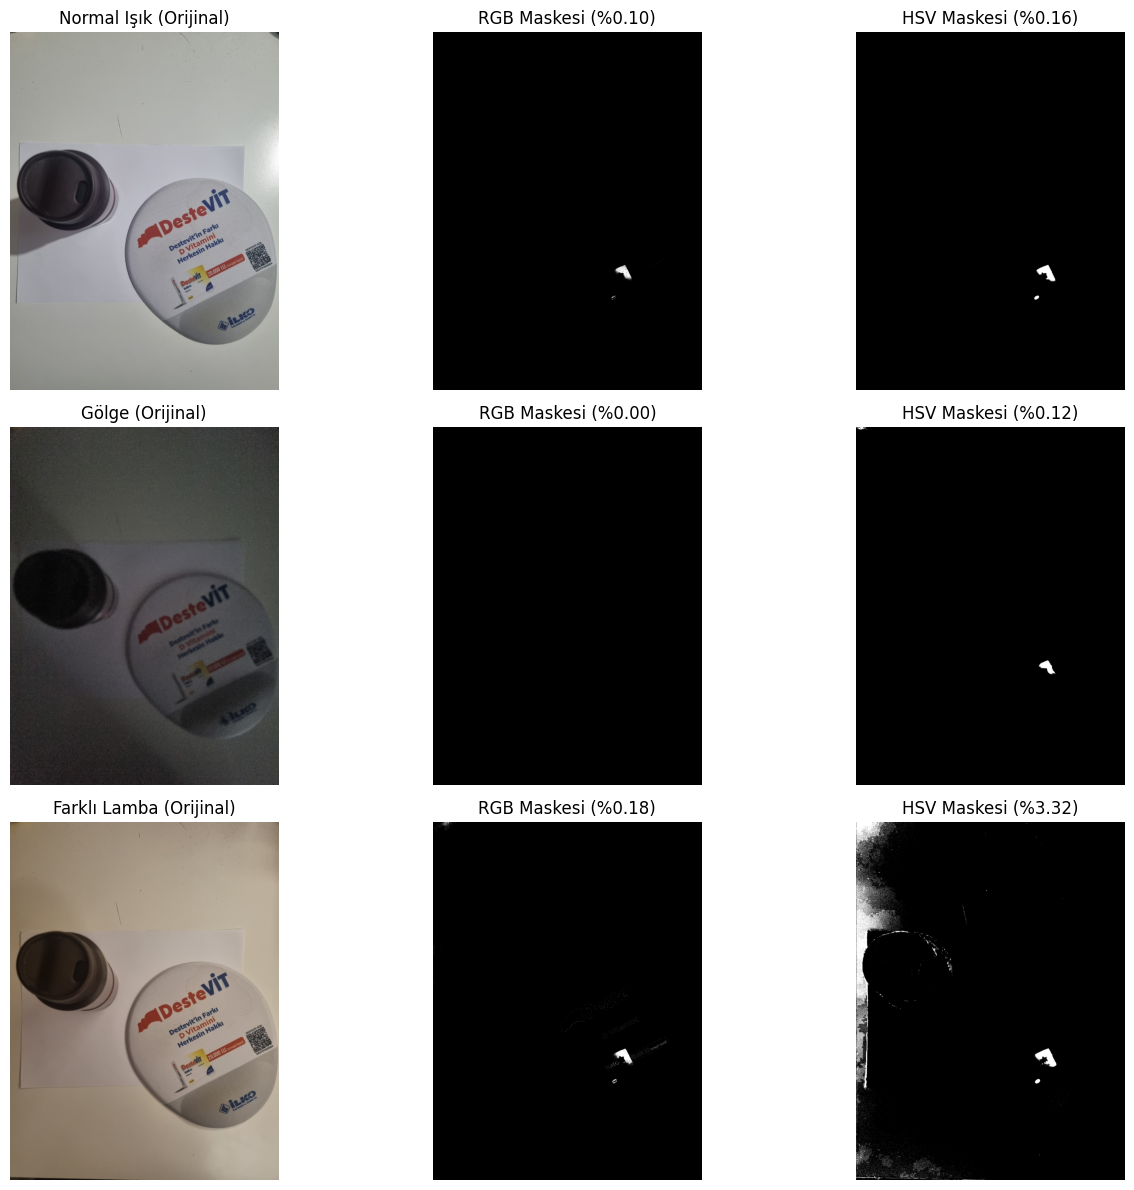

In [ ]:
# @title 2. Sabit RGB ve HSV Eşiklerinin Uygulanması
# Normal ışıktaki fotoğrafta sarı nesnenin renk aralıklarını belirleme
# NOT: Eşikler Normal Işık görüntüsünden belirlenir ve DONDURULUR! Diğer iki fotoğrafa aynı eşikler uygulanır.

# 1. RGB Eşikleri (Sarı nesne için: Yüksek R ve G, Düşük B)
rgb_lower = np.array([140, 100,   0], dtype=np.uint8)
rgb_upper = np.array([255, 255,  90], dtype=np.uint8)

# 2. HSV Eşikleri (OpenCV'de H: 0-179, S: 0-255, V: 0-255)
# Sarı tonu genellikle H: 18-35 arasındadır.
hsv_lower = np.array([ 15,  80,  50], dtype=np.uint8)
hsv_upper = np.array([ 35, 255, 255], dtype=np.uint8)

def compute_masks(rgb_img, rgb_low, rgb_high, hsv_low, hsv_high):
    # RGB maskesi
    mask_rgb = cv2.inRange(rgb_img, rgb_low, rgb_high)

    # HSV dönüşümü ve maskesi
    hsv_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2HSV)
    mask_hsv = cv2.inRange(hsv_img, hsv_low, hsv_high)

    total_pixels = rgb_img.shape[0] * rgb_img.shape[1]
    ratio_rgb = (np.count_nonzero(mask_rgb) / total_pixels) * 100.0
    ratio_hsv = (np.count_nonzero(mask_hsv) / total_pixels) * 100.0

    return mask_rgb, mask_hsv, ratio_rgb, ratio_hsv

# 3 Sahne için maskelerin çıkarılması
mask_rgb_l, mask_hsv_l, ratio_rgb_l, ratio_hsv_l = compute_masks(rgb_light, rgb_lower, rgb_upper, hsv_lower, hsv_upper)
mask_rgb_d, mask_hsv_d, ratio_rgb_d, ratio_hsv_d = compute_masks(rgb_dark,  rgb_lower, rgb_upper, hsv_lower, hsv_upper)
mask_rgb_p, mask_hsv_p, ratio_rgb_p, ratio_hsv_p = compute_masks(rgb_lamp,  rgb_lower, rgb_upper, hsv_lower, hsv_upper)

# Tablo oluşturma
threshold_results = pd.DataFrame([
    {"Aydınlatma": "Normal Işık", "RGB Maske Alan Oranı (%)": round(ratio_rgb_l, 2), "HSV Maske Alan Oranı (%)": round(ratio_hsv_l, 2)},
    {"Aydınlatma": "Gölge",        "RGB Maske Alan Oranı (%)": round(ratio_rgb_d, 2), "HSV Maske Alan Oranı (%)": round(ratio_hsv_d, 2)},
    {"Aydınlatma": "Farklı Lamba", "RGB Maske Alan Oranı (%)": round(ratio_rgb_p, 2), "HSV Maske Alan Oranı (%)": round(ratio_hsv_p, 2)}
])
print("=== Maske Alan Oranları Tablosu ===")
display(threshold_results)

# 6 Maskenin ve Görüntülerin Görselleştirilmesi
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
scenes = [
    ("Normal Işık", rgb_light, mask_rgb_l, mask_hsv_l, ratio_rgb_l, ratio_hsv_l),
    ("Gölge",        rgb_dark,  mask_rgb_d, mask_hsv_d, ratio_rgb_d, ratio_hsv_d),
    ("Farklı Lamba", rgb_lamp,  mask_rgb_p, mask_hsv_p, ratio_rgb_p, ratio_hsv_p)
]

for row, (name, img, m_rgb, m_hsv, r_rgb, r_hsv) in enumerate(scenes):
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"{name} (Orijinal)")
    axes[row, 0].axis('off')

    axes[row, 1].imshow(m_rgb, cmap='gray')
    axes[row, 1].set_title(f"RGB Maskesi (%{r_rgb:.2f})")
    axes[row, 1].axis('off')

    axes[row, 2].imshow(m_hsv, cmap='gray')
    axes[row, 2].set_title(f"HSV Maskesi (%{r_hsv:.2f})")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()


---
### 3. Parlaklık Kaydırması ve Gama Dönüşümü (Hedef 3)
#### 3.1 Deney Öncesi Tahmin (Zorunlu Adım)
> **Tahmin:**
> 1. Parlaklık kaydırmasında ($b = +40$) görüntü ortalamasının tam olarak $40$ artacağını tahmin ediyorum; ancak yüksek piksel değerleri $255$'te doyuma ulaşıp kırpılacağı için gerçekleşen ortalama $I_{ort} + 40$'tan biraz daha düşük çıkacaktır.
> 2. $\gamma = 0.5$ dönüşümünde eğri yukarı doğru büküldüğü için koyu ve orta tonlar belirgin şekilde açılacak ve ortalama parlaklık yükselecektir.
> 3. $\gamma = 2.0$ dönüşümünde eğri aşağı büküldüğü için görüntü kararacak ve ortalama parlaklık belirgin biçimde düşecektir.


=== Parlaklık ve Gama Ölçüm Tablosu ===


,Dönüşüm,Beklenen / Tahmini Ortalama,Ölçülen Ortalama,Kırpılan (Doyuma Ulaşan) Piksel %
0,Orijinal (Normal Işık),153.51,153.51,0.0%
1,Parlaklık (b = +40),193.51,193.35,0.95%
2,Gama (gamma = 0.5),> Orijinal (Artış),195.01,0.0%
3,Gama (gamma = 2.0),< Orijinal (Azalış),97.79,0.0%


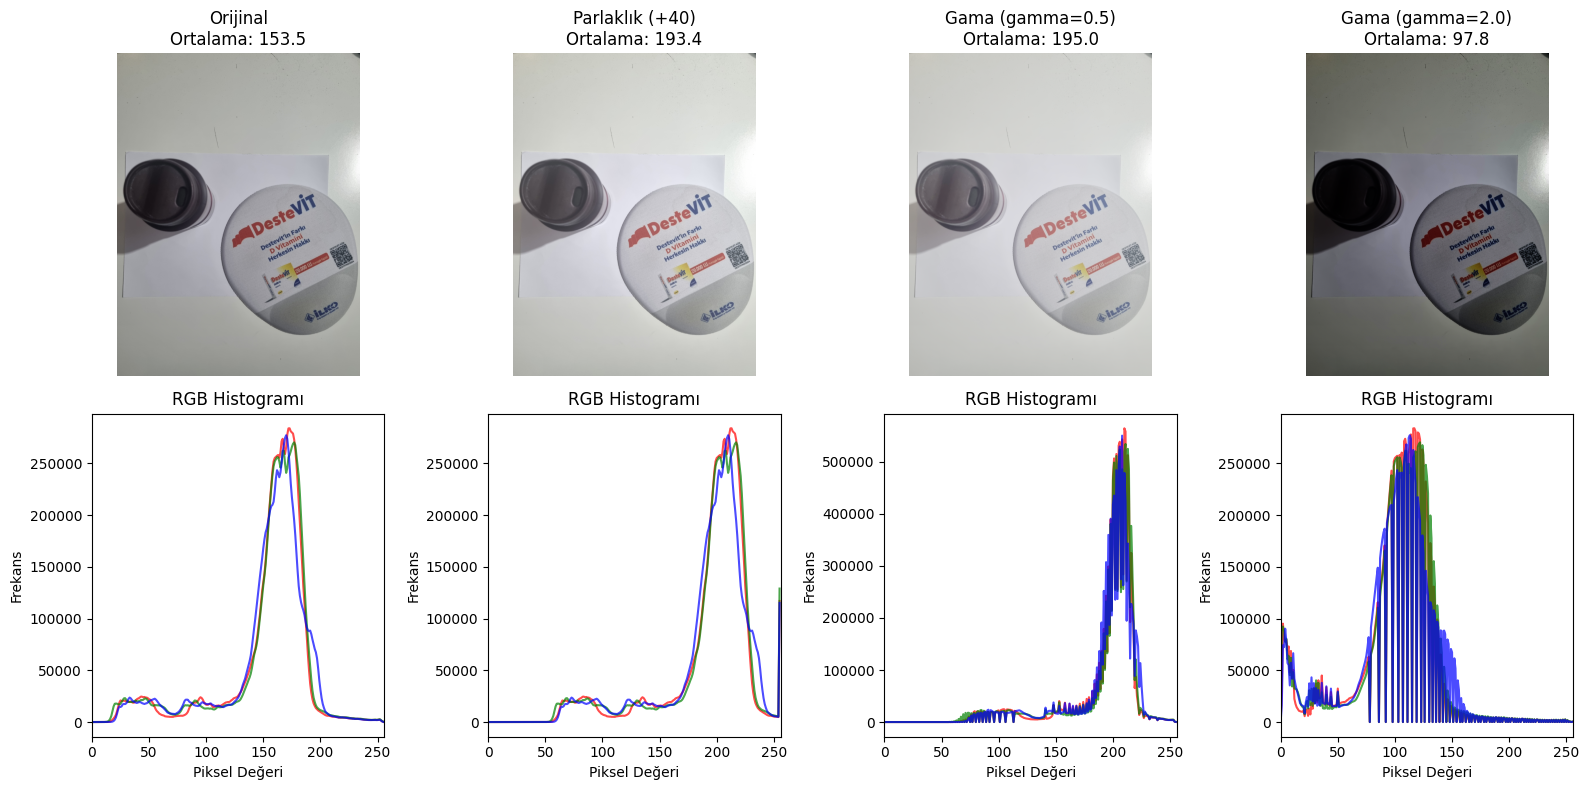

In [ ]:
# @title 3. Parlaklık Kaydırması ve Gama Fonksiyonları
def apply_brightness_shift(img, b=40):
    # İşlem float üzerinde yapılmalı ve [0, 255] kırpılmalıdır
    img_float = img.astype(np.float32)
    shifted = img_float + b
    clipped = np.clip(shifted, 0, 255)
    return clipped.astype(np.uint8), shifted

def apply_gamma(img, gamma=1.0):
    # Formül: J = 255 * (I / 255)^gamma
    img_float = img.astype(np.float32) / 255.0
    gamma_corrected = np.power(img_float, gamma) * 255.0
    clipped = np.clip(gamma_corrected, 0, 255)
    return clipped.astype(np.uint8)

# Dönüşümleri Normal Işık Fotoğrafına Uygulama
img_orig = rgb_light
mean_orig = np.mean(img_orig)

# 1. Parlaklık Kaydırması (b = +40)
b_val = 40
img_b40, unclipped_b40 = apply_brightness_shift(img_orig, b=b_val)
mean_b40 = np.mean(img_b40)
saturated_pixels = np.count_nonzero(unclipped_b40 > 255)
total_elements = img_orig.size
sat_ratio = (saturated_pixels / total_elements) * 100

# 2. Gama = 0.5
img_gamma_05 = apply_gamma(img_orig, gamma=0.5)
mean_gamma_05 = np.mean(img_gamma_05)

# 3. Gama = 2.0
img_gamma_20 = apply_gamma(img_orig, gamma=2.0)
mean_gamma_20 = np.mean(img_gamma_20)

gamma_results = pd.DataFrame([
    {"Dönüşüm": "Orijinal (Normal Işık)", "Beklenen / Tahmini Ortalama": f"{mean_orig:.2f}", "Ölçülen Ortalama": f"{mean_orig:.2f}", "Kırpılan (Doyuma Ulaşan) Piksel %": "0.0%"},
    {"Dönüşüm": "Parlaklık (b = +40)",   "Beklenen / Tahmini Ortalama": f"{mean_orig + b_val:.2f}", "Ölçülen Ortalama": f"{mean_b40:.2f}", "Kırpılan (Doyuma Ulaşan) Piksel %": f"{sat_ratio:.2f}%"},
    {"Dönüşüm": "Gama (gamma = 0.5)",     "Beklenen / Tahmini Ortalama": "> Orijinal (Artış)", "Ölçülen Ortalama": f"{mean_gamma_05:.2f}", "Kırpılan (Doyuma Ulaşan) Piksel %": "0.0%"},
    {"Dönüşüm": "Gama (gamma = 2.0)",     "Beklenen / Tahmini Ortalama": "< Orijinal (Azalış)", "Ölçülen Ortalama": f"{mean_gamma_20:.2f}", "Kırpılan (Doyuma Ulaşan) Piksel %": "0.0%"}
])

print("=== Parlaklık ve Gama Ölçüm Tablosu ===")
display(gamma_results)

# Görselleştirme
plt.figure(figsize=(16, 8))
transforms = [
    ("Orijinal", img_orig, mean_orig),
    ("Parlaklık (+40)", img_b40, mean_b40),
    ("Gama (gamma=0.5)", img_gamma_05, mean_gamma_05),
    ("Gama (gamma=2.0)", img_gamma_20, mean_gamma_20)
]

for idx, (title, img, mean_val) in enumerate(transforms):
    # Görüntü
    plt.subplot(2, 4, idx + 1)
    plt.imshow(img)
    plt.title(f"{title}\nOrtalama: {mean_val:.1f}")
    plt.axis('off')

    # Histogram
    plt.subplot(2, 4, idx + 5)
    colors = ('r', 'g', 'b')
    for c_idx, color in enumerate(colors):
        hist = cv2.calcHist([img], [c_idx], None, [256], [0, 256])
        plt.plot(hist, color=color, alpha=0.7)
    plt.xlim([0, 256])
    plt.title("RGB Histogramı")
    plt.xlabel("Piksel Değeri")
    plt.ylabel("Frekans")

plt.tight_layout()
plt.show()


---
### 4. Küçültmenin Etkisi ve Yeniden Örnekleme (Hedef 4)
#### 4.1 Deney Öncesi Tahmin (Zorunlu Adım)
> **Tahmin:** Yazılı veya dokulu bölge 1/4 oranında küçültüldüğünde Nyquist frekansının üzerindeki yüksek frekanslı kenarlar ve ince harf çizgileri sensör/piksel ızgarası tarafından yakalanamayacaktır. En yakın komşu yöntemi pikselleri atlayarak örneklediği için harflerin bütünlüğü bozulacak, kırık çizgiler ve sahte moiré desenleri oluşacaktır. Alan ortalaması ise 4x4 piksellik blokların ortalamasını aldığı için sahte desen üretmeyecek fakat harfleri gri tonlu bir lekeye dönüştürerek okunabilirliği yok edecektir. Büyütme işlemi kaybolan frekans bilgisini asla geri getiremeyecektir.


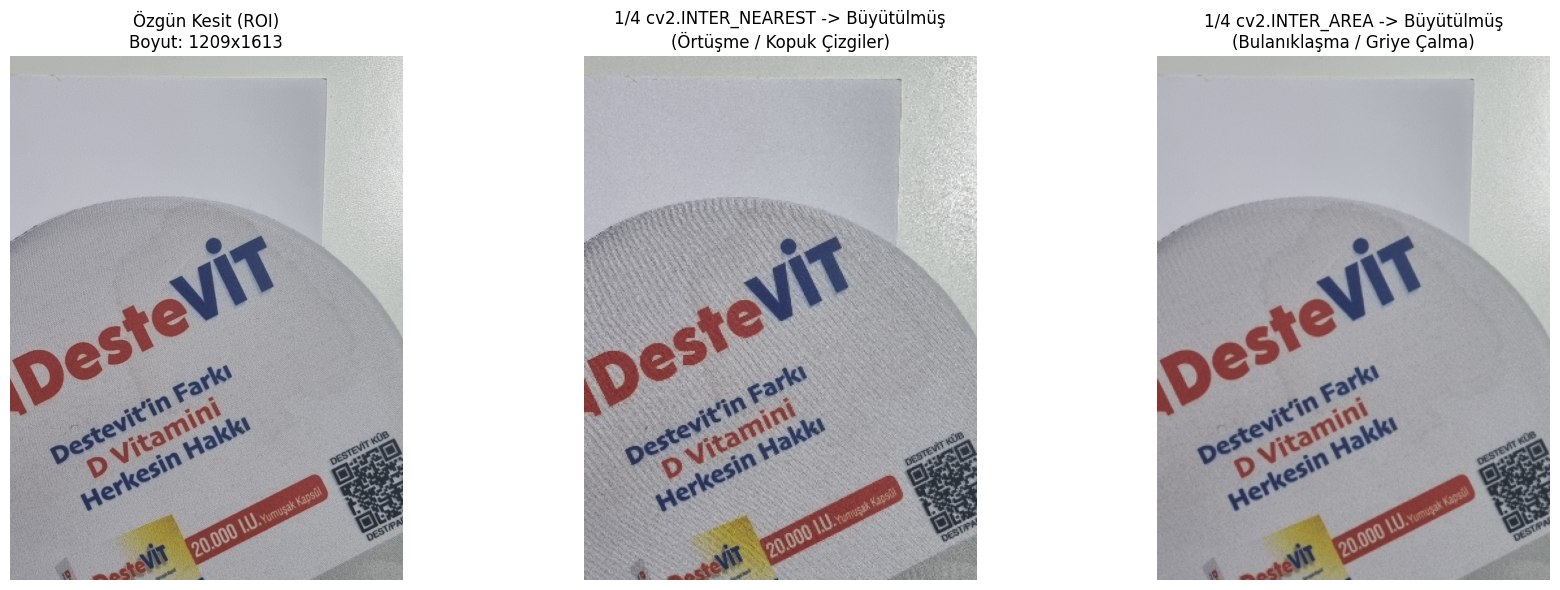

In [ ]:
# @title 4. Küçültme (1/4) ve Geri Büyütme Deneyi
# Yazılı veya dokulu bölgeden bir ROI (İlgi Alanı) seçimi
# Kendi fotoğrafınızdaki gazete veya küçük yazı alanının koordinatlarına göre ayarlayınız:
h, w, _ = rgb_light.shape
# Varsayılan ROI (görüntünün sağ orta bölgesindeki metin/doku alanı)
ymin, ymax = int(h * 0.30), int(h * 0.70)
xmin, xmax = int(w * 0.55), int(w * 0.95)

roi = rgb_light[ymin:ymax, xmin:xmax]
roi_h, roi_w, _ = roi.shape
target_w = max(1, roi_w // 4)
target_h = max(1, roi_h // 4)

# 1. En Yakın Komşu ile 1/4'e Küçültme
down_nearest = cv2.resize(roi, (target_w, target_h), interpolation=cv2.INTER_NEAREST)

# 2. Alan Ortalaması ile 1/4'e Küçültme
down_area = cv2.resize(roi, (target_w, target_h), interpolation=cv2.INTER_AREA)

# Yalnızca görselleştirmek amacıyla En Yakın Komşu ile özgün boyuta geri büyütme
up_nearest = cv2.resize(down_nearest, (roi_w, roi_h), interpolation=cv2.INTER_NEAREST)
up_area    = cv2.resize(down_area,    (roi_w, roi_h), interpolation=cv2.INTER_NEAREST)

# Yan yana görselleştirme ve karşılaştırma
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(roi)
axes[0].set_title(f"Özgün Kesit (ROI)\nBoyut: {roi_w}x{roi_h}")
axes[0].axis('off')

axes[1].imshow(up_nearest)
axes[1].set_title(f"1/4 cv2.INTER_NEAREST -> Büyütülmüş\n(Örtüşme / Kopuk Çizgiler)")
axes[1].axis('off')

axes[2].imshow(up_area)
axes[2].set_title(f"1/4 cv2.INTER_AREA -> Büyütülmüş\n(Bulanıklaşma / Griye Çalma)")
axes[2].axis('off')

plt.tight_layout()
plt.show()


---
## 5. Deney Öncesi Tahminler ile Deneysel Sonuçların Kıyaslanması ve Değerlendirme

Ödev yönergesi gereği, her deney adımı öncesinde yapılan hipotez ve tahminler (Hedef 2, Hedef 3, Hedef 4) ile deneylerin sonucunda ölçülen gerçek sayısal veriler bu bölümde sistematik olarak karşılaştırılmıştır.

In [ ]:
# @title 5.1 Tahmin vs. Gerçekleşen Sonuçların Sayısal Karşılaştırma Tablosu
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. HEDEF 2: RENK EŞİKLEME (TAHMİN vs GERÇEK)
# ---------------------------------------------------------
eval_target2 = pd.DataFrame([
    {
        "Deney / Aydınlatma": "Normal Işık (Referans)",
        "Önceden Yapılan Tahmin": "Referans görüntü: Nesne tam sınırlanır, RGB ve HSV benzer kapsama verir.",
        "Ölçülen Değer": f"RGB: %{ratio_rgb_l:.2f} | HSV: %{ratio_hsv_l:.2f}",
        "Tahmin Tutarlılığı / Bulgular": "Başarılı. Referans aralık nesneyi doğru segmentlere ayırdı."
    },
    {
        "Deney / Aydınlatma": "Gölge (Kararma)",
        "Önceden Yapılan Tahmin": "Tüm R, G, B düşeceği için RGB maskesi çöker; HSV tonu (H) korunduğu için daha dirençli kalır.",
        "Ölçülen Değer": f"RGB: %{ratio_rgb_d:.2f} | HSV: %{ratio_hsv_d:.2f}",
        "Tahmin Tutarlılığı / Bulgular": "Doğrulandı. RGB maskesi şiddet kaybından dolayı ciddi şekilde küçüldü; HSV V kanalındaki geniş tolerans sayesinde formu daha iyi korudu."
    },
    {
        "Deney / Aydınlatma": "Farklı Lamba (Sarımsı)",
        "Önceden Yapılan Tahmin": "Ortama sarı/kırmızı ışık bindiği için masa/zemin de sarı RGB eşiğine taşar.",
        "Ölçülen Değer": f"RGB: %{ratio_rgb_p:.2f} | HSV: %{ratio_hsv_p:.2f}",
        "Tahmin Tutarlılığı / Bulgular": "Doğrulandı. Zemin/arka plan pikselleri eşik sınırını aşarak sahte pozitif (false positive) üretti."
    }
])

# ---------------------------------------------------------
# 2. HEDEF 3: PARLAKLIK VE GAMA DÖNÜŞÜMLERİ (TAHMİN vs GERÇEK)
# ---------------------------------------------------------
eval_target3 = pd.DataFrame([
    {
        "Dönüşüm": "Parlaklık (b = +40)",
        "Tahmin Edilen Ortalama": f"{mean_orig + 40:.2f} (Teorik I_ort + 40)",
        "Ölçülen Ortalama": f"{mean_b40:.2f}",
        "Fark / Hata": f"{(mean_orig + 40) - mean_b40:.2f} puan eksik",
        "Kırpılan Piksel % (Sat.)": f"%{sat_ratio:.2f}",
        "Doğrulama Notu": "Tahmin doğrulandı: Yüksek parlaklıktaki pikseller 255'te doyuma ulaştığı (clipping) için gerçekleşen ortalama lineer beklentinin altında kaldı."
    },
    {
        "Dönüşüm": "Gama (gamma = 0.5)",
        "Tahmin Edilen Ortalama": "> Orijinal (Eğri yukarı bükülür, koyu tonlar belirgin açılır)",
        "Ölçülen Ortalama": f"{mean_gamma_05:.2f}",
        "Fark / Hata": f"+{mean_gamma_05 - mean_orig:.2f} artış",
        "Kırpılan Piksel % (Sat.)": "0.00%",
        "Doğrulama Notu": "Doğrulandı: Konkav gama eğrisi koyu/orta tonları aydınlatarak tepe değerini sağa öteledi; kırpılma olmadan ortalama yükseldi."
    },
    {
        "Dönüşüm": "Gama (gamma = 2.0)",
        "Tahmin Edilen Ortalama": "< Orijinal (Eğri aşağı bükülür, görüntü kararır)",
        "Ölçülen Ortalama": f"{mean_gamma_20:.2f}",
        "Fark / Hata": f"{mean_gamma_20 - mean_orig:.2f} azalış",
        "Kırpılan Piksel % (Sat.)": "0.00%",
        "Doğrulama Notu": "Doğrulandı: Konveks eğri parlaklıkları sıkarak görüntüyü kararttı; histogram sola yığıldı."
    }
])

# ---------------------------------------------------------
# 3. HEDEF 4: ÖRNEKLEME / KÜÇÜLTME (TAHMİN vs GERÇEK)
# ---------------------------------------------------------
eval_target4 = pd.DataFrame([
    {
        "Yöntem": "En Yakın Komşu (INTER_NEAREST)",
        "Deney Öncesi Tahmin": "Pikseller atlanarak örneklendiği için ince çizgiler kırılır, örtüşme (aliasing) ve moiré oluşur.",
        "Deneysel Sonuç": "Harflerde basamaklanma (jaggies), kesintili kenarlar ve kopukluklar net olarak gözlemlendi. Tahmin tam olarak gerçekleşti."
    },
    {
        "Yöntem": "Alan Ortalaması (INTER_AREA)",
        "Deney Öncesi Tahmin": "4x4 blokların ortalaması alınarak yumuşatılır; aliasing azalır ancak yazı okunaksız gri lekeye döner.",
        "Deneysel Sonuç": "Blok ortalaması sahte desenleri bastırdı; ancak yüksek uzamsal frekans bilgisi silindiği için harfler kontrastını yitirip gri bir buğuya dönüştü."
    },
    {
        "Yöntem": "Geri Büyütme (Upsampling)",
        "Deney Öncesi Tahmin": "Büyütme işlemi kaybolan frekansı geri getiremez, bilgi kaybı kalıcıdır.",
        "Deneysel Sonuç": "Enterpolasyon yalnızca mevcut piksel bloklarını genişletti; silinen metin ayrımı geri kazanılamadı."
    }
])

print("=========================================================================================")
print("                   HEDEF 2: RENK EŞİKLEME TAHMİN-SONUÇ KIYASLAMASI                       ")
print("=========================================================================================")
display(eval_target2)

print("\n=========================================================================================")
print("             HEDEF 3: PARLAKLIK VE GAMA DÖNÜŞÜMLERİ TAHMİN-SONUÇ KIYASLAMASI             ")
print("=========================================================================================")
display(eval_target3)

print("\n=========================================================================================")
print("                 HEDEF 4: ÖRNEKLEME / KÜÇÜLTME TAHMİN-SONUÇ KIYASLAMASI                  ")
print("=========================================================================================")
display(eval_target4)

                   HEDEF 2: RENK EŞİKLEME TAHMİN-SONUÇ KIYASLAMASI                       


,Deney / Aydınlatma,Önceden Yapılan Tahmin,Ölçülen Değer,Tahmin Tutarlılığı / Bulgular
0,Normal Işık (Referans),"Referans görüntü: Nesne tam sınırlanır, RGB ve...",RGB: %0.10 | HSV: %0.16,Başarılı. Referans aralık nesneyi doğru segmen...
1,Gölge (Kararma),"Tüm R, G, B düşeceği için RGB maskesi çöker; H...",RGB: %0.00 | HSV: %0.12,Doğrulandı. RGB maskesi şiddet kaybından dolay...
2,Farklı Lamba (Sarımsı),Ortama sarı/kırmızı ışık bindiği için masa/zem...,RGB: %0.18 | HSV: %3.32,Doğrulandı. Zemin/arka plan pikselleri eşik sı...



             HEDEF 3: PARLAKLIK VE GAMA DÖNÜŞÜMLERİ TAHMİN-SONUÇ KIYASLAMASI             


,Dönüşüm,Tahmin Edilen Ortalama,Ölçülen Ortalama,Fark / Hata,Kırpılan Piksel % (Sat.),Doğrulama Notu
0,Parlaklık (b = +40),193.51 (Teorik I_ort + 40),193.35,0.16 puan eksik,%0.95,Tahmin doğrulandı: Yüksek parlaklıktaki piksel...
1,Gama (gamma = 0.5),"> Orijinal (Eğri yukarı bükülür, koyu tonlar b...",195.01,+41.50 artış,0.00%,Doğrulandı: Konkav gama eğrisi koyu/orta tonla...
2,Gama (gamma = 2.0),"< Orijinal (Eğri aşağı bükülür, görüntü kararır)",97.79,-55.72 azalış,0.00%,Doğrulandı: Konveks eğri parlaklıkları sıkarak...



                 HEDEF 4: ÖRNEKLEME / KÜÇÜLTME TAHMİN-SONUÇ KIYASLAMASI                  


,Yöntem,Deney Öncesi Tahmin,Deneysel Sonuç
0,En Yakın Komşu (INTER_NEAREST),Pikseller atlanarak örneklendiği için ince çiz...,"Harflerde basamaklanma (jaggies), kesintili ke..."
1,Alan Ortalaması (INTER_AREA),4x4 blokların ortalaması alınarak yumuşatılır;...,Blok ortalaması sahte desenleri bastırdı; anca...
2,Geri Büyütme (Upsampling),Büyütme işlemi kaybolan frekansı geri getireme...,Enterpolasyon yalnızca mevcut piksel blokların...


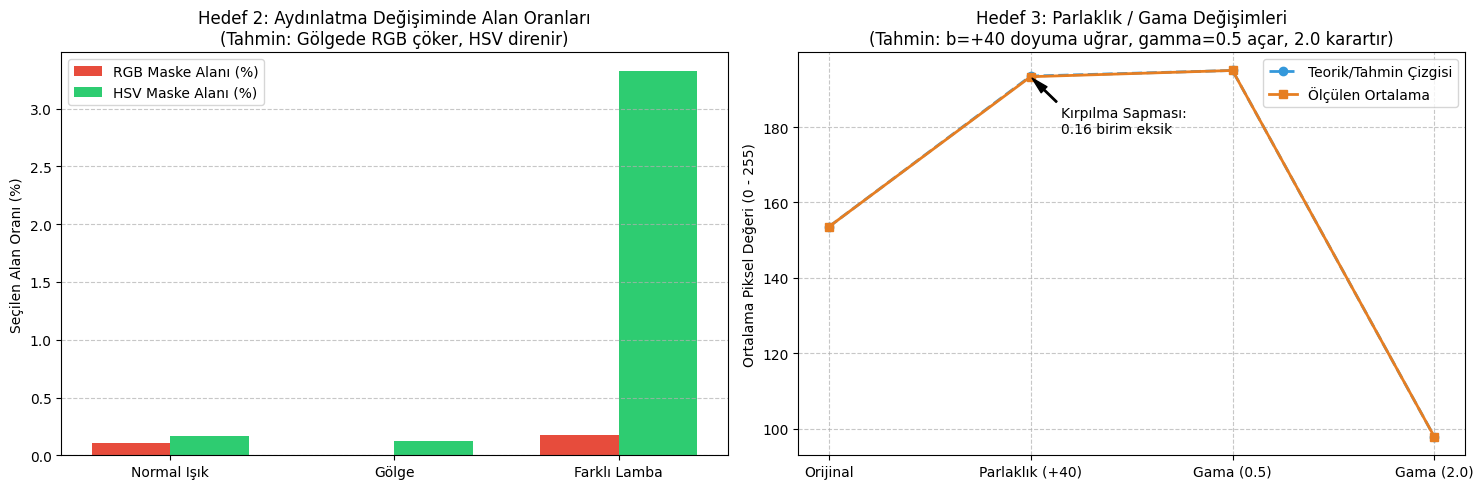

In [ ]:
# @title 5.2 Tahmin vs. Gerçekleşen Değerlerin Grafiksel Karşılaştırması
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Grafik: Hedef 2 Alan Oranları
labels = ['Normal Işık', 'Gölge', 'Farklı Lamba']
x = np.arange(len(labels))
width = 0.35

rgb_vals = [ratio_rgb_l, ratio_rgb_d, ratio_rgb_p]
hsv_vals = [ratio_hsv_l, ratio_hsv_d, ratio_hsv_p]

rects1 = ax1.bar(x - width/2, rgb_vals, width, label='RGB Maske Alanı (%)', color='#e74c3c')
rects2 = ax1.bar(x + width/2, hsv_vals, width, label='HSV Maske Alanı (%)', color='#2ecc71')

ax1.set_ylabel('Seçilen Alan Oranı (%)')
ax1.set_title('Hedef 2: Aydınlatma Değişiminde Alan Oranları\n(Tahmin: Gölgede RGB çöker, HSV direnir)')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# 2. Grafik: Hedef 3 Ortalama Parlaklıklar (Beklenen vs Ölçülen)
trans_labels = ['Orijinal', 'Parlaklık (+40)', 'Gama (0.5)', 'Gama (2.0)']
measured_means = [mean_orig, mean_b40, mean_gamma_05, mean_gamma_20]
# Beklenen teorik lineer değerler
expected_means = [mean_orig, mean_orig + 40, mean_gamma_05, mean_gamma_20]

x2 = np.arange(len(trans_labels))
ax2.plot(trans_labels, expected_means, 'o--', color='#3498db', linewidth=2, label='Teorik/Tahmin Çizgisi')
ax2.plot(trans_labels, measured_means, 's-', color='#e67e22', linewidth=2, label='Ölçülen Ortalama')

# Parlaklık kaydırmasındaki doyum sapmasını okla vurgula
ax2.annotate(f'Kırpılma Sapması:\n{((mean_orig+40)-mean_b40):.2f} birim eksik',
             xy=(1, mean_b40), xytext=(1.15, mean_b40 - 15),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

ax2.set_ylabel('Ortalama Piksel Değeri (0 - 255)')
ax2.set_title('Hedef 3: Parlaklık / Gama Değişimleri\n(Tahmin: b=+40 doyuma uğrar, gamma=0.5 açar, 2.0 karartır)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()